In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os, subprocess, sys, warnings
from sklearn.linear_model import LinearRegression
from sklearn.inspection import permutation_importance

In [ ]:
df=pd.read_csv('/content/train-test.csv')

In [ ]:
df.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [ ]:
df.shape

(48000, 14)

In [ ]:
df.dtypes

,0
load_id,object
pickup,object
delivery,object
pickup_lat,float64
pickup_lon,float64
delivery_lat,float64
delivery_lon,float64
distance,float64
equipment,object
weight,float64


In [ ]:
df.drop(columns=['load_id'],inplace=True)

In [ ]:
df[df.duplicated()]

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate


In [ ]:
df.isnull().sum()

,0
pickup,0
delivery,0
pickup_lat,0
pickup_lon,0
delivery_lat,0
delivery_lon,0
distance,0
equipment,0
weight,300
date,0


In [ ]:
df['date'] = pd.to_datetime(df['date'])

In [ ]:
df.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,date,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,48000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,2025-05-31 19:53:29.400000,1.083387,2.062468,2373.980682
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,2025-01-01 00:00:00,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,2025-03-18 00:00:00,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,2025-05-31 00:00:00,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,2025-08-15 00:00:00,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,2025-10-31 00:00:00,1.467780,3.610350,25533.000000
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,NaN,0.168091,0.291391,1486.493245


### Applying Univaraite Analysis

In [ ]:
numeric_cols=df.dtypes[df.dtypes!='object'].index

In [ ]:
numeric_cols

Index(['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance',
       'weight', 'date', 'market_index', 'quote_signal', 'posted_rate'],
      dtype='object')

In [ ]:
cat_cols=df.dtypes[df.dtypes=='object'].index

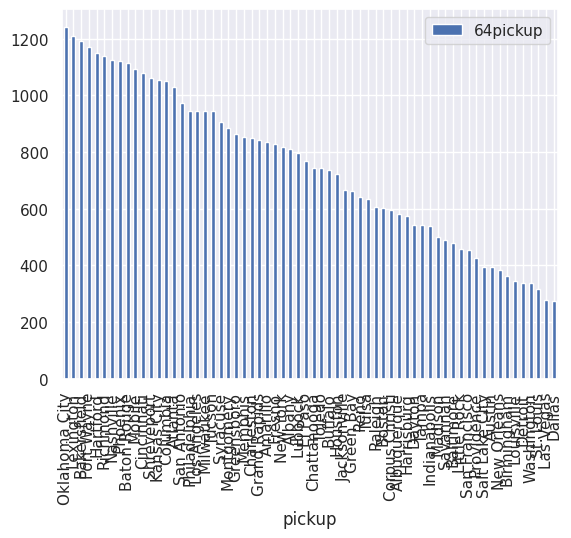

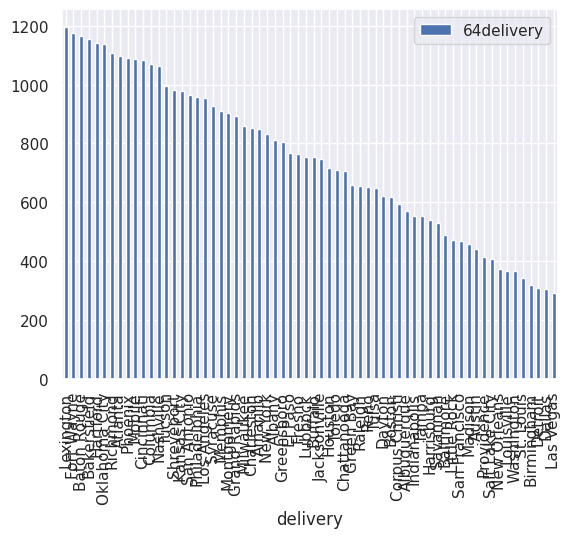

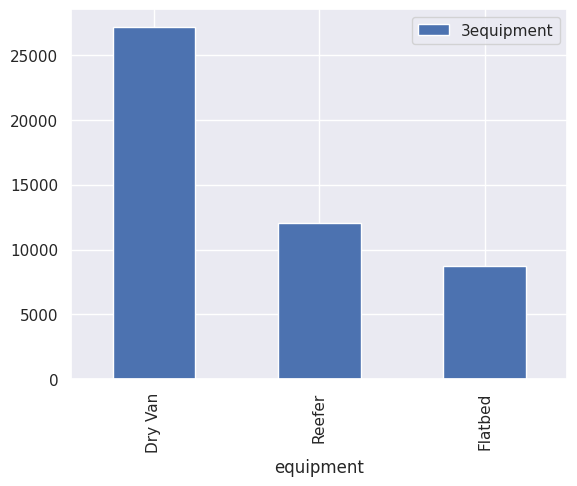

In [ ]:
for col in cat_cols:
    counts=df[col].value_counts()
    counts.plot(kind='bar')
    plt.legend([f"{len(counts.index)}{col}"])
    plt.show()

In [ ]:
numeric_cols

Index(['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance',
       'weight', 'date', 'market_index', 'quote_signal', 'posted_rate'],
      dtype='object')

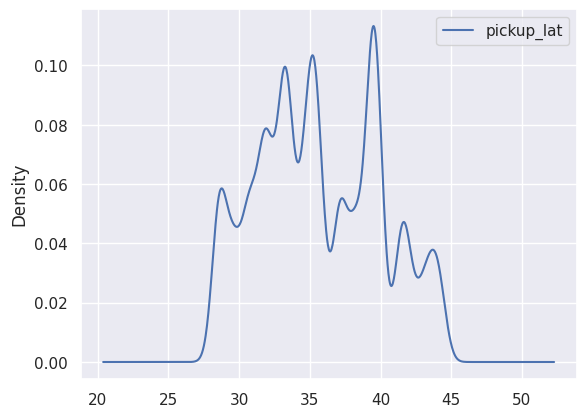

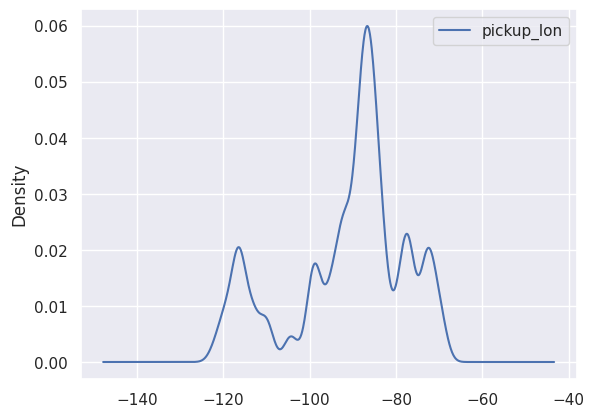

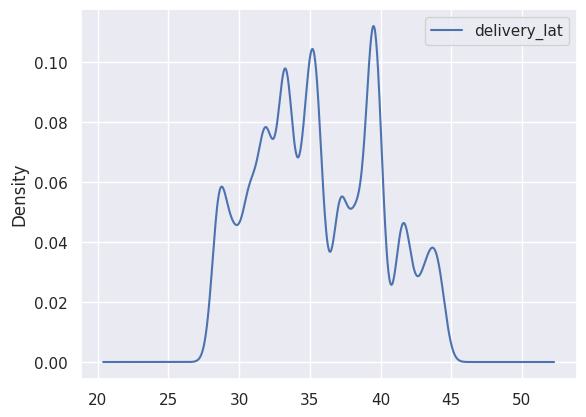

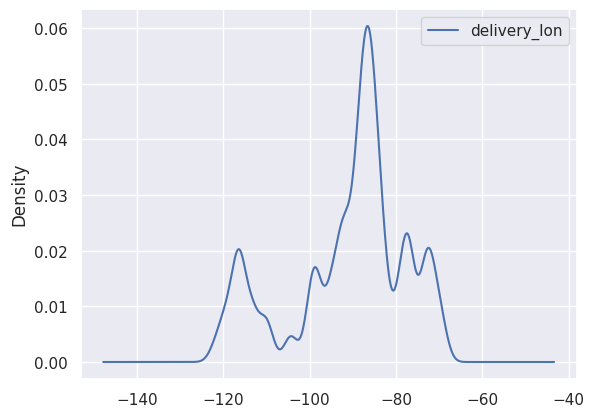

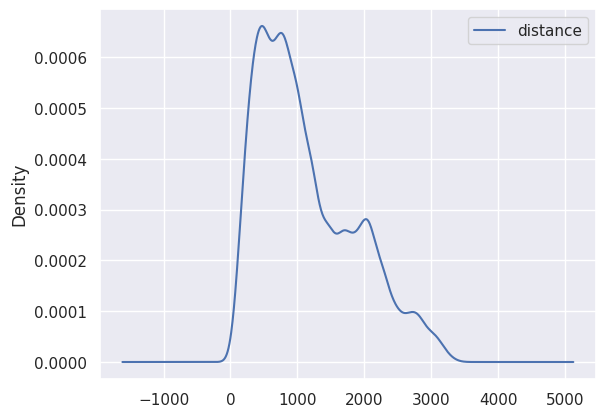

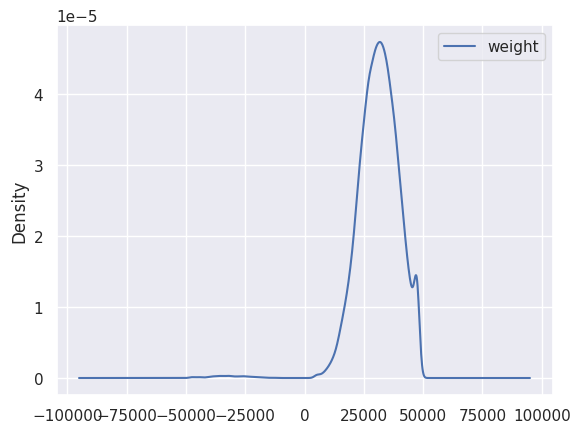

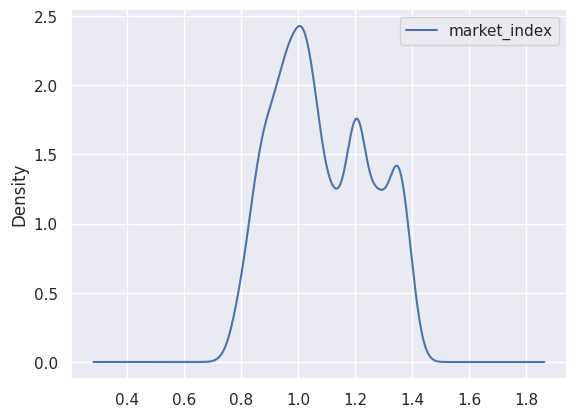

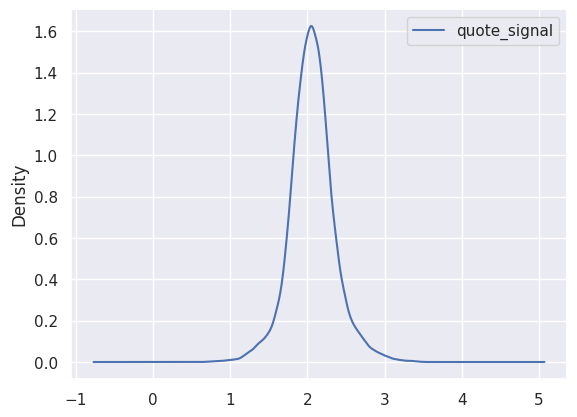

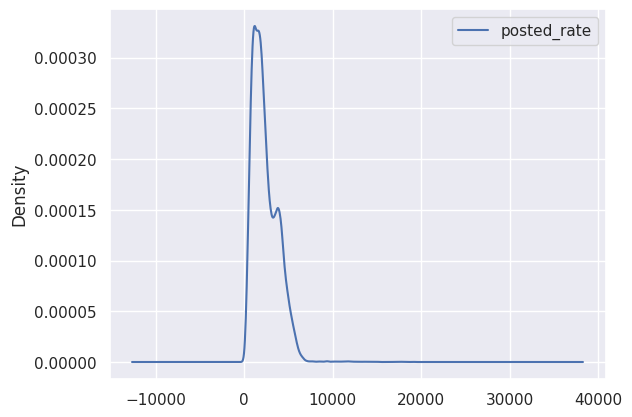

In [ ]:
for col in numeric_cols:
    if col=='date':
       continue
    df[col].plot(kind='kde')
    plt.legend([f"{col}"])
    plt.show()

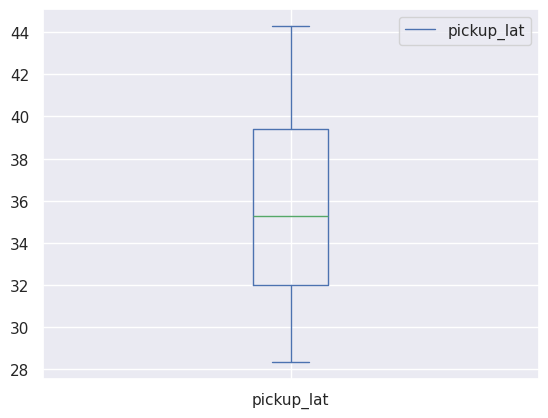

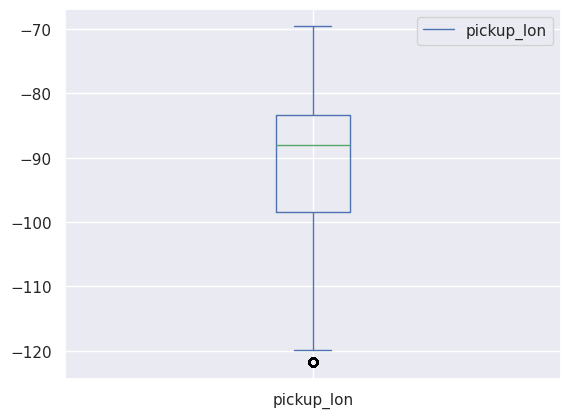

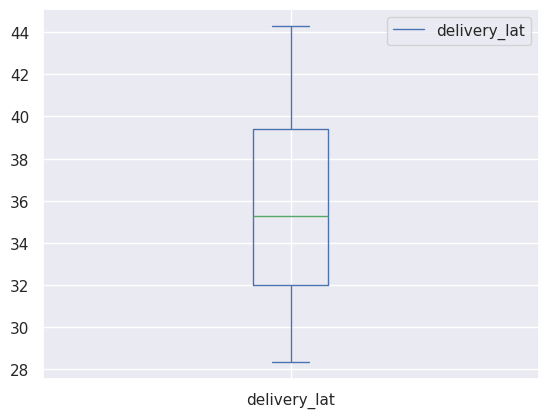

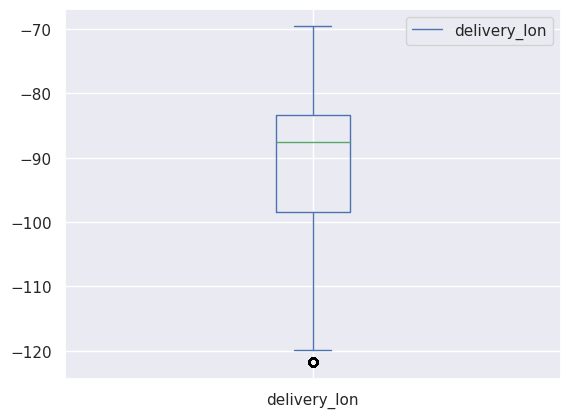

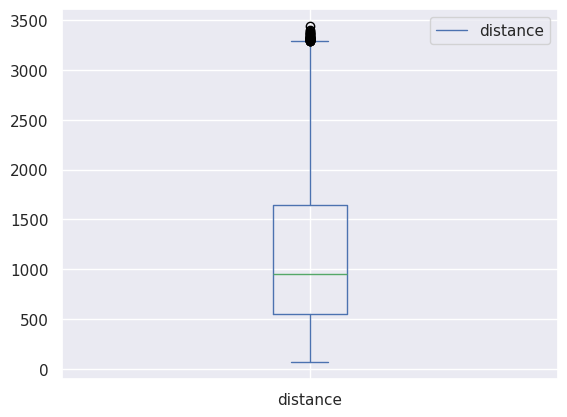

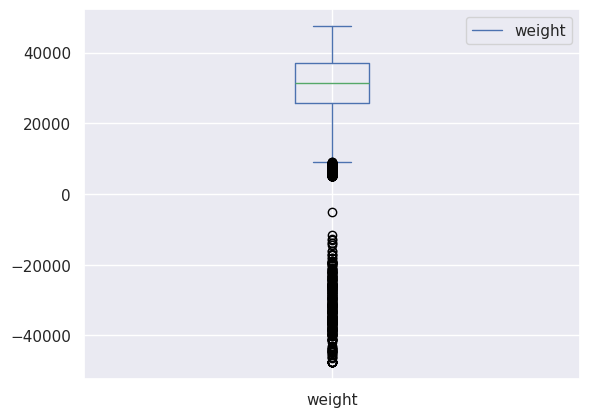

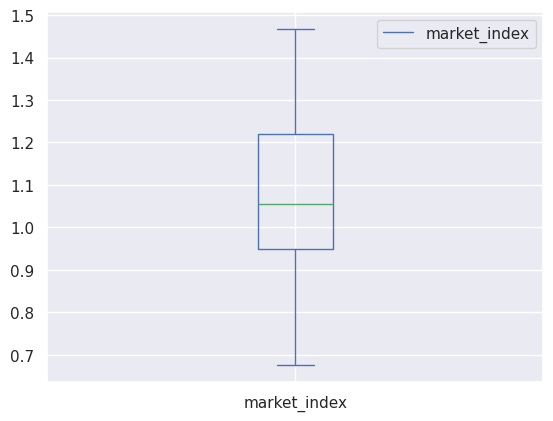

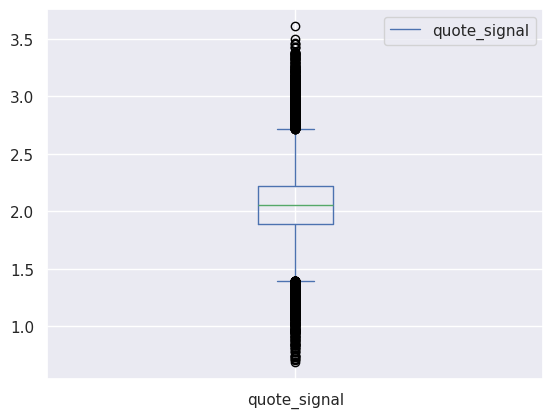

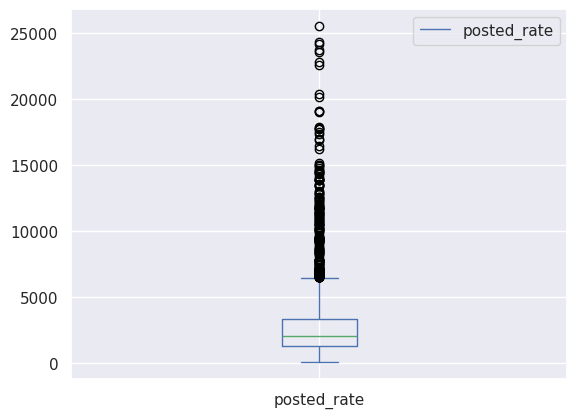

In [ ]:
for col in numeric_cols:
    if col=='date':
      continue
    df[col].plot(kind='box')
    plt.legend([f"{col}"])
    plt.show()

## Let explore the Records where weight Column have outlier

In [ ]:
filtered_df = df[(df["weight"] <0)]

In [ ]:
filtered_df.head(5)

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
68,Amarillo,Dayton,33.17137,-104.36789,39.87206,-85.62931,1334.2,Reefer,-36559.0,2025-01-01,0.96102,2.11777,2831.27
204,Fresno,Tucson,33.07921,-119.79528,30.92733,-113.23037,496.2,Dry Van,-26670.0,2025-01-02,0.96903,2.13155,1046.92
206,Columbia,Raleigh,34.63570,-83.28506,35.37376,-77.47605,411.3,Reefer,-20003.0,2025-01-02,0.94800,2.31682,959.15
225,Greensboro,Lubbock,35.98195,-82.78379,29.87534,-99.85456,1317.4,Reefer,-23981.0,2025-01-02,1.00820,2.13918,2836.00
376,Madison,Providence,41.70243,-89.85588,37.37287,-69.50000,1331.1,Dry Van,-41397.0,2025-01-03,0.94787,1.91867,2522.54


In [ ]:
without_outlier_df=df[(df["weight"] > 0)]

In [ ]:
without_outlier_df

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28
...,...,...,...,...,...,...,...,...,...,...,...,...,...
47995,Reno,Baton Rouge,39.54838,-118.64843,30.50134,-92.65374,1830.9,Flatbed,31786.0,2025-10-31,0.98865,2.05626,3787.32
47996,Greensboro,Memphis,35.98195,-82.78379,35.56802,-89.52871,445.8,Reefer,37465.0,2025-10-31,1.03034,1.51985,1171.93
47997,Greensboro,Cincinnati,35.98195,-82.78379,37.15706,-86.77499,267.9,Flatbed,24528.0,2025-10-31,1.00846,1.46954,713.36
47998,Memphis,Reno,35.56802,-89.52871,39.54838,-118.64843,1901.3,Flatbed,37581.0,2025-10-31,1.00014,2.05132,3987.46


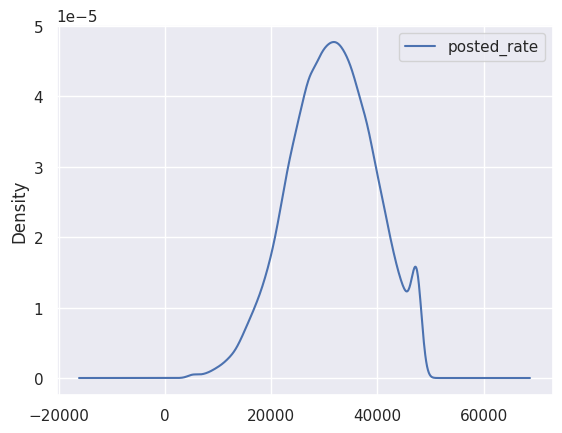

In [ ]:
without_outlier_df['weight'].plot(kind='kde')
plt.legend([f"{col}"])
plt.show()

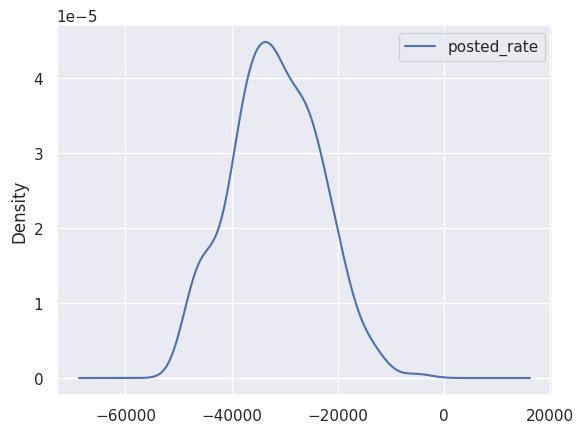

In [ ]:
filtered_df['weight'].plot(kind='kde')
plt.legend([f"{col}"])
plt.show()

### Distribution of negative weights value and positive weights value are approximate same so it indicated that weights values are correct but they need to be positive

In [ ]:
df["weight"] = df["weight"].abs()

<Axes: ylabel='weight'>

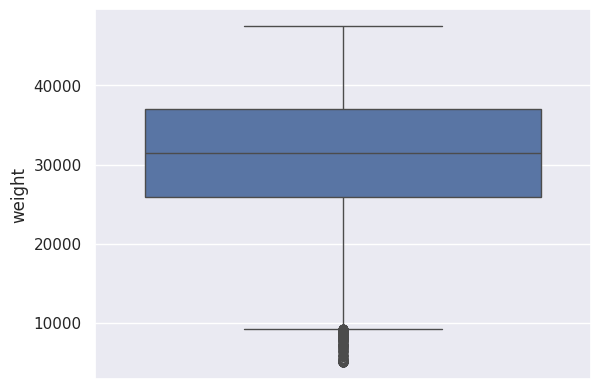

In [ ]:
sns.boxplot(df['weight'])

### Created Feature From Date Columns for Furthure analysis

In [ ]:
df['month']=df['date'].dt.month

In [ ]:
df['day']=df['date'].dt.day_name()

In [ ]:
df['month_end']=df['date'].dt.is_month_end

In [ ]:
df['month_start']=df['date'].dt.is_month_start

In [ ]:
df.head()

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,month,day,month_end,month_start
0,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41,1,Wednesday,False,True
1,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97,1,Wednesday,False,True
2,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54,1,Wednesday,False,True
3,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28,1,Wednesday,False,True
4,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28,1,Wednesday,False,True


In [ ]:
def show_plots_according_to_date_components(column):

  avg_weight_by_day = (
      df.groupby("day")[column].mean().reset_index()
  )

  # Plot 1: Bar Plot (Comparing exact values)
  sns.barplot(
      x=avg_weight_by_day["day"],
      y=avg_weight_by_day[column],
      # palette="Blues_d",
  )
  plt.show()


  avg_weight_by_day = (
      df.groupby("month")[column].mean().reset_index()
  )

  # Plot 1: Bar Plot (Comparing exact values)
  sns.barplot(
      x=avg_weight_by_day["month"],
      y=avg_weight_by_day[column],
      # palette="Blues_d",
  )
  plt.show()
  sns.kdeplot(x=column,data=df,hue='month_end')
  plt.show()



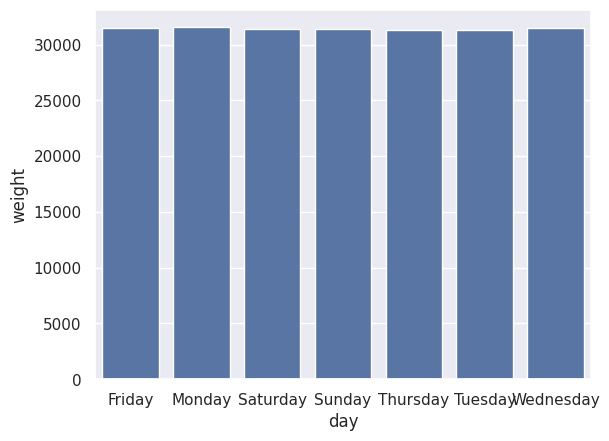

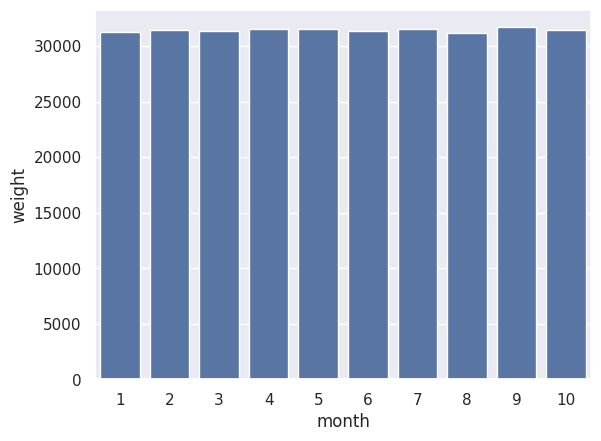

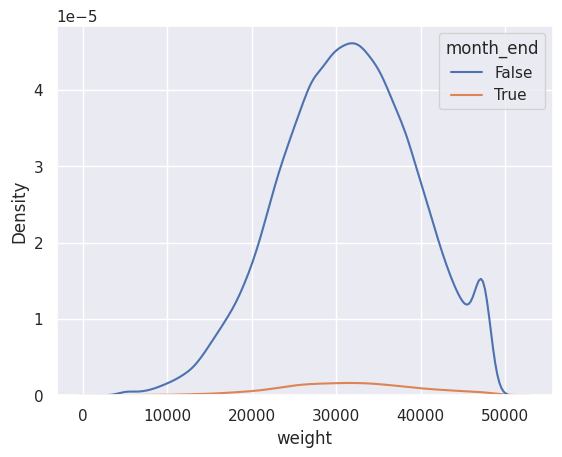

In [ ]:
show_plots_according_to_date_components(column='weight')

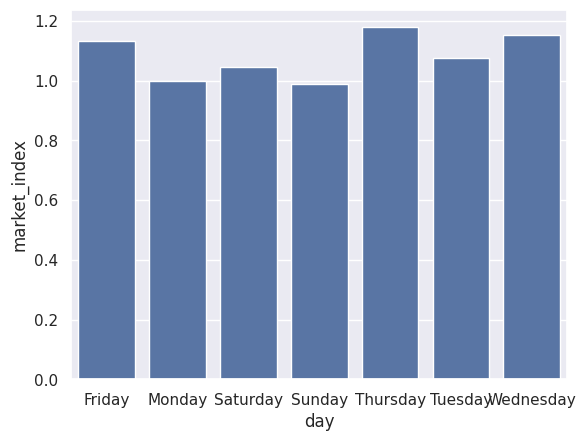

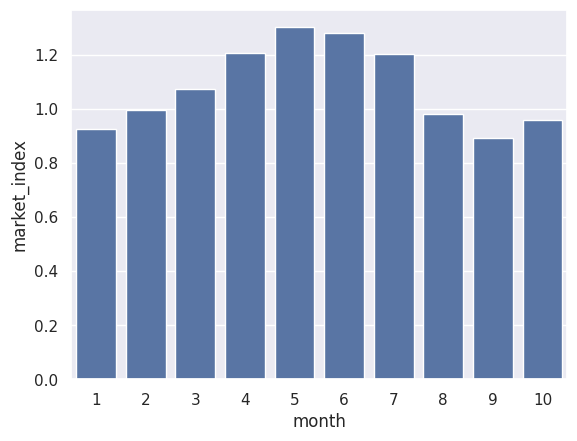

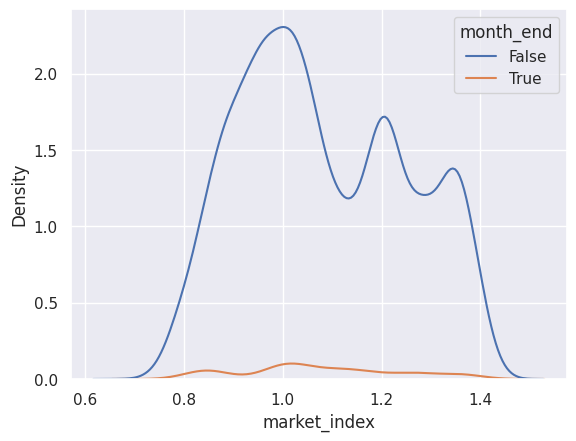

In [ ]:
show_plots_according_to_date_components(column='market_index')

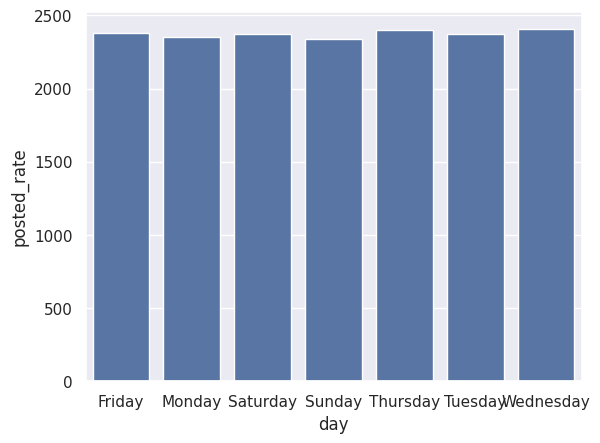

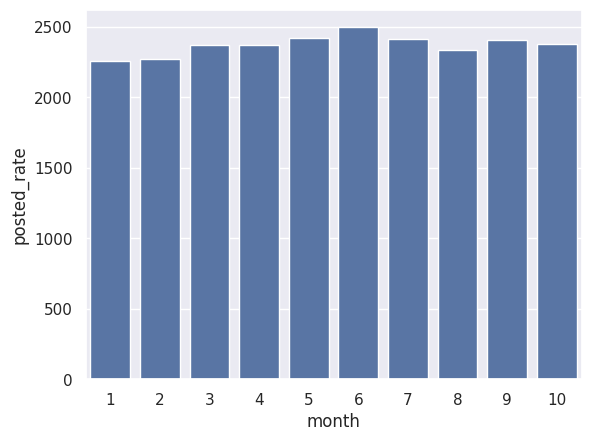

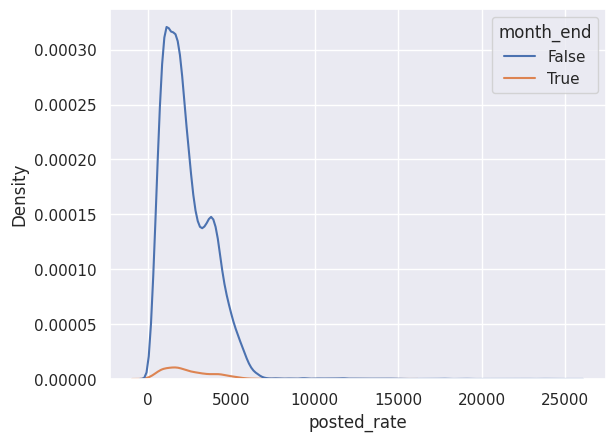

In [ ]:
show_plots_according_to_date_components(column='posted_rate')

### Let check Correlation

In [ ]:
numeric_cols=df.dtypes[df.dtypes!='object'].index

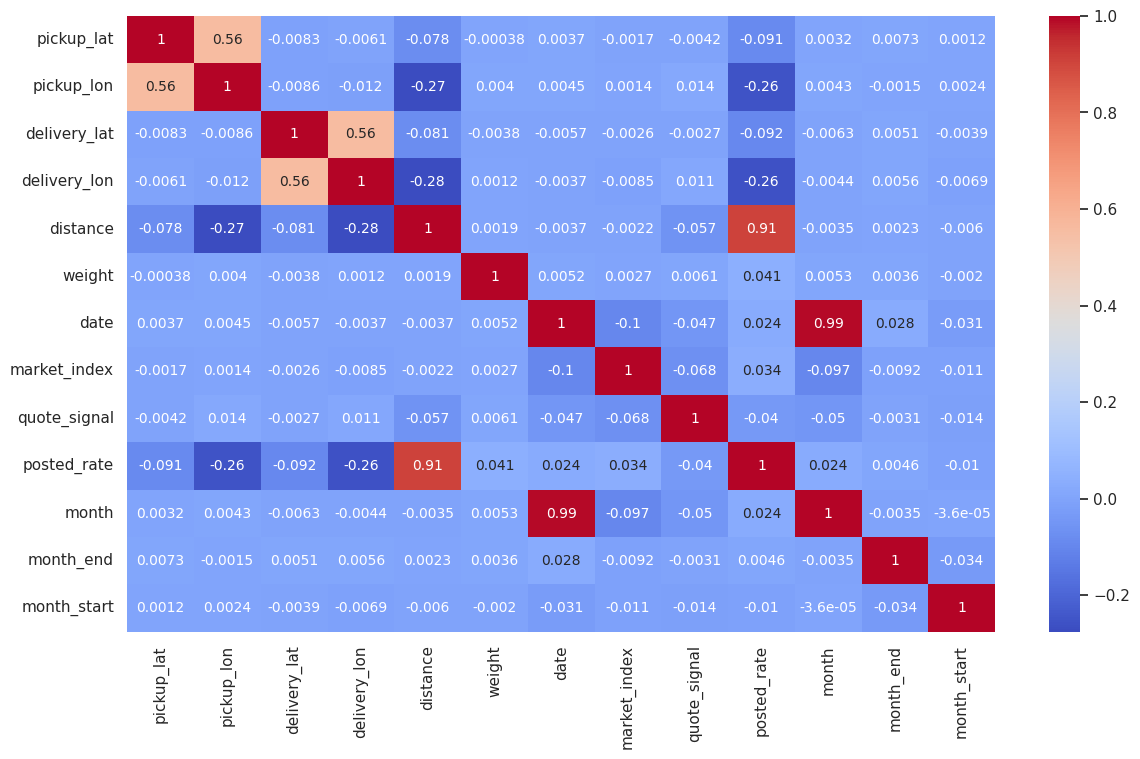

In [ ]:
# 1. Correctly set up the figure size using plt.subplots
fig, ax = plt.subplots(figsize=(14, 8))

# 2. Pass the created 'ax' object to the seaborn heatmap
sns.heatmap(df[numeric_cols].corr(), annot=True, ax=ax, cmap="coolwarm",annot_kws={'size':10})

# 3. Display the plot
plt.show()

### So important cols for Posted rate are
#### distance higher effect,
#### pickup longitude and delievery logitude good effect
#### and here are some weak column who can contribute in combination, month_start, weight,market_index, quote_signal, and some categorical cols, date/month

### Let's check movement of Posted Rate over time to check whether any time series thing exist or not

In [ ]:
df = df.sort_values("date")

In [ ]:
df=df.set_index('date')

In [ ]:
df=df.reset_index()

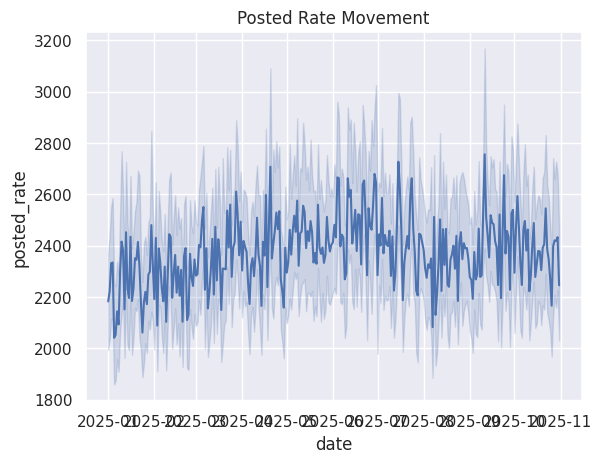

In [ ]:
sns.set_theme(style="darkgrid")

# Create a clean line plot
sns.lineplot(data=df, x="date", y="posted_rate")

plt.title("Posted Rate Movement")
plt.show()

##### This Graphs shows that average price per day stays almost the same all year, between about $2,200 and $2,600. Prices vary a lot each day because the data has both short trips and long trips.

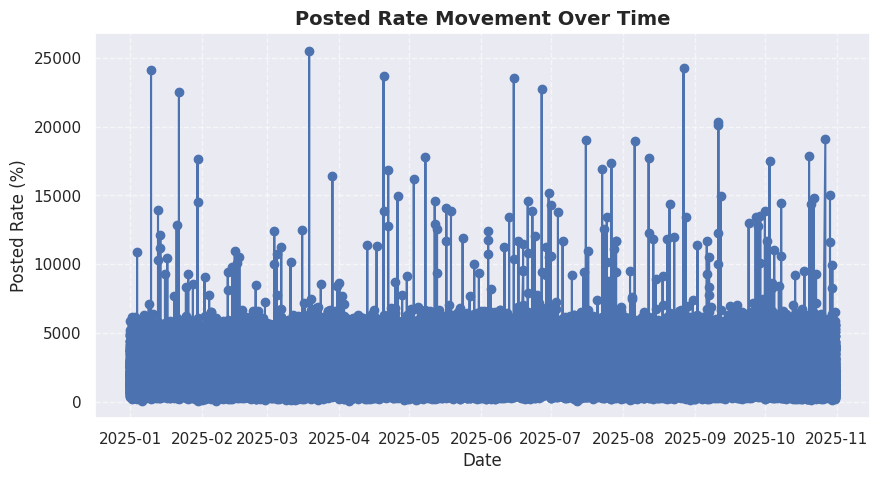

In [ ]:
# 4. Plot the movement
plt.figure(figsize=(10, 5))
plt.plot(
    df["date"], df["posted_rate"], marker="o", linestyle="-", color="b"
)

# 5. Format the chart
plt.title("Posted Rate Movement Over Time", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Posted Rate (%)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)

#### Most loads cost less than 6,000$ in every month. A few loads cost much more (up to 25,000$), and they appear in every month, so there is no clear pattern over time.

### let find Average Rate per Mile by Month and Truck Type

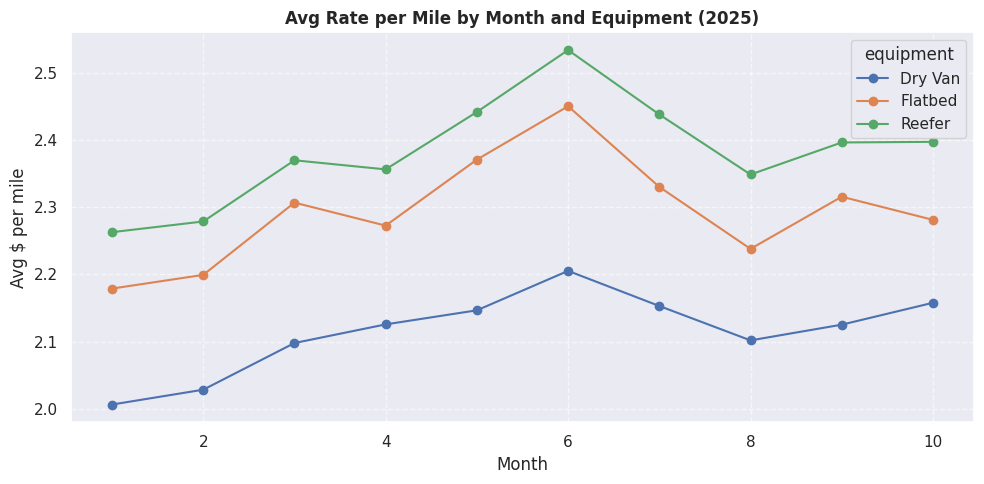

In [ ]:
df["rpm"] = df["posted_rate"] / df["distance"]

monthly = (df.groupby(["month", "equipment"])["rpm"]
             .mean()
             .unstack())

ax = monthly.plot(marker="o", figsize=(10, 5))
ax.set_title("Avg Rate per Mile by Month and Equipment (2025)", fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Avg $ per mile")
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

#### Conclusion
- **Truck type sets the price.** Reefer costs the most every month, then Flatbed, then Dry Van. On average Reefer costs about 13% more than Dry Van ($2.38 vs $2.12 per mile).
- **Prices change with the month.** All three lines rise from January to a peak in June (about +10% to +12%), then fall a little.
- **The month effect is similar for all truck types**, because the lines are almost parallel.
- So `equipment` and `month` are useful inputs for the model.

## A. Data-quality checks

In [ ]:
val = pd.read_csv(f"/content/validation.csv", parse_dates=["date"])   # 12,000 loads WITHOUT the answer
val["weight"] = val["weight"].abs()      # the SAME fix on validation, so both files look alike making weight column positive

print("df shape:", df.shape, "| val shape:", val.shape)
print("df dates:", df.date.min().date(), "->", df.date.max().date())
print("val dates:", val.date.min().date(), "->", val.date.max().date())
print("negative weights left -> df:", (df.weight < 0).sum(), "| val:", (val.weight < 0).sum())

df shape: (48000, 18) | val shape: (12000, 13)
df dates: 2025-01-01 -> 2025-10-31
val dates: 2025-11-01 -> 2025-12-31
negative weights left -> df: 0 | val: 0


### Conclusion
- Training file (df): 48,000 loads from **Jan 1 to Oct 31**. Validation file: 12,000 loads from **Nov 1 to Dec 31**.
- The validation loads are **in the future** compared with the training loads. This one fact decides how we split the data later (by time, never at random).

In [ ]:
miss = pd.DataFrame({"df_missing": df.isna().sum(), "val_missing": val.isna().sum()})
miss = miss[(miss.df_missing > 0) | (miss.val_missing > 0)]               # keep only columns that have gaps
miss["df_%"] = (miss.df_missing / len(df) * 100).round(2)
miss["val_%"] = (miss.val_missing / len(val) * 100).round(2)
print(miss)


              df_missing  val_missing  df_%  val_%
market_index       374.0        249.0  0.78   2.08
weight             300.0        165.0  0.62   1.38


In [ ]:
# market_index is an INPUT (not the answer), so it is allowed to use both files to learn each day's average value.
all_feat = pd.concat([df[["date", "market_index"]], val[["date", "market_index"]]])
daily_mi = all_feat.groupby("date")["market_index"].mean()      # one average value per calendar day
print(daily_mi)
print("Days covered:", len(daily_mi), "|", daily_mi.index.min().date(), "->", daily_mi.index.max().date())
print("Days with no market_index at all:", daily_mi.isna().sum())

date
2025-01-01    0.961224
2025-01-02    0.986606
2025-01-03    0.940339
2025-01-04    0.857702
2025-01-05    0.801855
                ...   
2025-12-27    0.914528
2025-12-28    0.858023
2025-12-29    0.869552
2025-12-30    0.944019
2025-12-31    1.027251
Name: market_index, Length: 365, dtype: float64
Days covered: 365 | 2025-01-01 -> 2025-12-31
Days with no market_index at all: 0


### Conclusion
- Only `market_index` (0.78% train, 2.08% validation) and `weight` (0.62%, 1.38%) have missing values, and very few.
- We keep all rows.
- `weight` is filled with mean/median, and  `market_index` is filled with that day's average.

In [ ]:
df.isnull().sum()

,0
date,0
pickup,0
delivery,0
pickup_lat,0
pickup_lon,0
delivery_lat,0
delivery_lon,0
distance,0
equipment,0
weight,300


In [ ]:
val.isnull().sum()

,0
load_id,0
pickup,0
delivery,0
pickup_lat,0
pickup_lon,0
delivery_lat,0
delivery_lon,0
distance,0
equipment,0
weight,165


####Outlier investigating

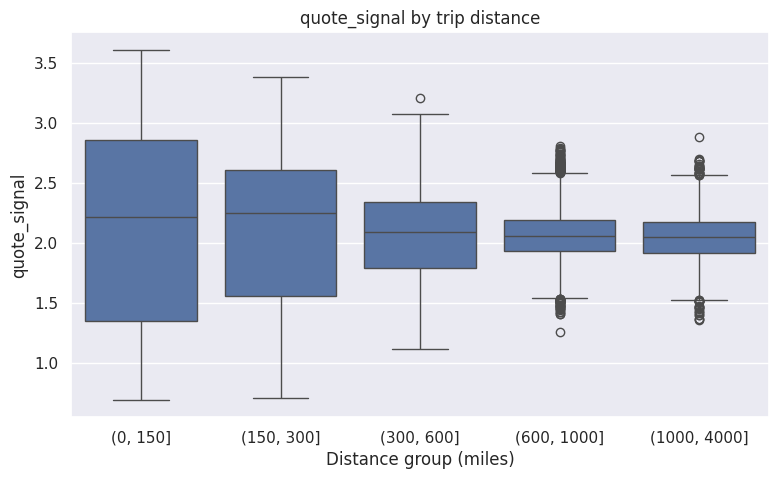

In [ ]:
df["distance_band"] = pd.cut(df["distance"], [0, 150, 300, 600, 1000, 4000])   # trips ko 5 groups me baant do

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="distance_band", y="quote_signal")                      # har group ka ek box
plt.title("quote_signal by trip distance")
plt.xlabel("Distance group (miles)"); plt.ylabel("quote_signal")
plt.show()

In [ ]:
df[['quote_signal','rpm']]

,quote_signal,rpm
0,2.39595,2.352935
1,2.16789,2.139092
2,1.81827,1.814089
3,1.90370,1.896506
4,1.78958,1.794100
...,...,...
47995,1.96459,2.214967
47996,1.35623,2.807011
47997,1.76458,2.395756
47998,2.24777,1.870004


#### Short trips naturally have more variation in quote_signal, while long trips tend to have more stable values. Therefore, it would be wrong to consider all high or low values as outliers. We should keep the data rows, but remove quote_signal from the model because it leaks information about the answer (target) during training.

## Feature Selection

In [ ]:
### these coumns can cause data leakage quote_signal, rpm,
# and others like distance_band, month_end, month_start are very less important column, created for analysis
### and also since we have latitude and longitude columns for both pickup location and delievery location
###  we don't need to use the pickup and delievery column beacuse it is unnecessary now

In [ ]:
df.head(1)

,date,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,market_index,quote_signal,posted_rate,month,day,month_end,month_start,rpm,distance_band
0,2025-01-01,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,0.95684,2.39595,645.41,1,Wednesday,False,True,2.352935,"(150, 300]"


In [ ]:
df=df.drop(columns=['pickup','delivery','quote_signal','day','month_end','month_start','rpm','distance_band'])

In [ ]:
df.head()

,date,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,market_index,posted_rate,month
0,2025-01-01,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,0.95684,645.41,1
1,2025-01-01,31.37602,-86.10743,39.62180,-88.48008,691.7,Dry Van,47500.0,0.95310,1479.61,1
2,2025-01-01,39.55328,-72.18051,41.70243,-89.85588,1098.0,Dry Van,29071.0,0.96395,1991.87,1
3,2025-01-01,39.55328,-72.18051,34.15334,-79.74475,684.1,Dry Van,25756.0,0.92209,1297.40,1
4,2025-01-01,28.56624,-116.70249,39.54838,-118.64843,891.6,Dry Van,21332.0,0.97336,1599.62,1


### Feature Transformation

In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer,TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.base import BaseEstimator, TransformerMixin


In [ ]:
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor,HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [ ]:
class MarketIndexImputer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()

        X.columns = ["date", "market_index"]
        X["date"] = pd.to_datetime(X["date"])

        # Learn average market index for each date
        self.daily_avg_ = X.groupby("date")["market_index"].mean()

        # Fallback if a date has no known market index
        self.global_avg_ = X["market_index"].mean()

        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()

        X.columns = ["date", "market_index"]
        X["date"] = pd.to_datetime(X["date"])

        missing = X["market_index"].isna()

        # Fill using that date's average learned during fit
        X.loc[missing, "market_index"] = (
            X.loc[missing, "date"].map(self.daily_avg_)
        )

        # Fallback for dates not seen during fit
        X["market_index"] = X["market_index"].fillna(
            self.global_avg_
        )

        return X[["market_index"]].to_numpy()

In [ ]:
numeric_features = [
    "weight",
    "distance",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon"
]

categorical_features = ["equipment"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore",
                             sparse_output=False))
])


In [ ]:
# Complete preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
        (
            "market",
            MarketIndexImputer(),
            ["date", "market_index"]
        ),
        ("month", "passthrough", ["month"])
    ],
    remainder="drop"
)

In [ ]:
df.head(1)

,date,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,market_index,posted_rate,month
0,2025-01-01,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,0.95684,645.41,1


In [ ]:
from sklearn.metrics import mean_absolute_percentage_error

In [ ]:

def time_based_cv(
    df,
    model_pipeline,
    n_folds=3,
    test_months=2,
    date_col="date",
    target="posted_rate",
    log_target=False
):
    data = df.copy()

    # Make sure date is datetime
    data[date_col] = pd.to_datetime(data[date_col])

    # Sort chronologically
    data = data.sort_values(date_col).reset_index(drop=True)

    # Last date in dataset
    end_of_data = data[date_col].max() + pd.Timedelta(days=1)

    results = []

    feature_cols = [
        'date',
        "pickup_lat",
        "pickup_lon",
        "delivery_lat",
        "delivery_lon",
        "distance",
        "equipment",
        "weight",
        "market_index",
        "month"
    ]

    for i in range(n_folds):

        # Define test period
        test_end = (
            end_of_data
            - pd.DateOffset(
                months=(n_folds - 1 - i) * test_months
            )
        )

        test_start = (
            test_end - pd.DateOffset(months=test_months)
        )

        # Train on past data; test on future data
        train = data[data[date_col] < test_start].copy()

        test = data[
            (data[date_col] >= test_start) &
            (data[date_col] < test_end)
        ].copy()

        # Guard against empty folds
        if train.empty or test.empty:
            raise ValueError(
                f"Fold {i + 1} has an empty train or test set. "
                "Reduce n_folds/test_months or check your dates."
            )

        X_train = train[feature_cols]
        y_train = train[target]

        X_test = test[feature_cols]
        y_test = test[target]

        # Fresh pipeline for this fold
        pipe = clone(model_pipeline)

        # Optional log transformation of target
        if log_target:
            if (y_train <= 0).any():
                raise ValueError(
                    "log_target=True requires all training "
                    "posted_rate values to be positive."
                )

            pipe = TransformedTargetRegressor(
                regressor=pipe,
                func=np.log,
                inverse_func=np.exp
            )

        # Train
        pipe.fit(X_train, y_train)

        # Predict
        train_pred = pipe.predict(X_train)
        test_pred = pipe.predict(X_test)

        # MAE
        train_mae = mean_absolute_error(
            y_train, train_pred
        )

        test_mae = mean_absolute_error(
            y_test, test_pred
        )

        # RMSE
        test_rmse = np.sqrt(
            mean_squared_error(y_test, test_pred)
        )

        # R²
        test_r2 = r2_score(y_test, test_pred)

        # MAPE: ignore zero actual values to avoid division by zero
        nonzero_mask = y_test != 0

        if nonzero_mask.any():
            test_mape = (
                mean_absolute_percentage_error(
                    y_test[nonzero_mask],
                    test_pred[nonzero_mask]
                ) * 100
            )
        else:
            test_mape = np.nan

        # Store fold results
        results.append({
            "fold": i + 1,
            "train_until": (
                test_start - pd.Timedelta(days=1)
            ).date(),
            "test_period": (
                f"{test_start.date()} to "
                f"{(test_end - pd.Timedelta(days=1)).date()}"
            ),
            "n_train": len(train),
            "n_test": len(test),
            "train_MAE": train_mae,
            "test_MAE": test_mae,
            "test_RMSE": test_rmse,
            "test_R2": test_r2,
            "test_MAPE_%": test_mape
        })

    results = pd.DataFrame(results)

    # Average metrics across folds
    average = results[
        [
            "train_MAE",
            "test_MAE",
            "test_RMSE",
            "test_R2",
            "test_MAPE_%"
        ]
    ].mean()

    return results, average

### One Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
lg=LinearRegression()

In [ ]:

lg_model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", lg)
])


In [ ]:
results,average_lg=time_based_cv(df, lg_model_pipeline,n_folds=3,test_months=2,date_col="date",target="posted_rate",log_target=True)

In [ ]:
results

,fold,train_until,test_period,n_train,n_test,train_MAE,test_MAE,test_RMSE,test_R2,test_MAPE_%
0,1,2025-04-30,2025-05-01 to 2025-06-30,19110,9696,437.136573,472.805388,963.779739,0.611900,22.199701
1,2,2025-06-30,2025-07-01 to 2025-08-31,28806,9671,452.104980,446.458581,968.706201,0.577668,21.437748
2,3,2025-08-31,2025-09-01 to 2025-10-31,38477,9523,452.944288,477.848926,978.990023,0.588455,22.419099


In [ ]:
average_lg

,0
train_MAE,447.395280
test_MAE,465.704298
test_RMSE,970.491988
test_R2,0.592674
test_MAPE_%,22.018850


### On Random Forest

In [ ]:

model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        max_features=0.75,
        max_samples=0.5
    ))
])


In [ ]:
results,average_rf=time_based_cv(df, model_pipeline,n_folds=3,test_months=2,date_col="date",target="posted_rate",log_target=True)

In [ ]:
results

,fold,train_until,test_period,n_train,n_test,train_MAE,test_MAE,test_RMSE,test_R2,test_MAPE_%
0,1,2025-04-30,2025-05-01 to 2025-06-30,19110,9696,70.866412,162.793296,654.830273,0.820838,6.849434
1,2,2025-06-30,2025-07-01 to 2025-08-31,28806,9671,73.432069,125.883369,630.943799,0.820836,5.465629
2,3,2025-08-31,2025-09-01 to 2025-10-31,38477,9523,73.605939,144.147255,644.087532,0.821864,6.295429


In [ ]:
average_rf

,0
train_MAE,88.900670
test_MAE,131.952234
test_RMSE,638.366237
test_R2,0.823917
test_MAPE_%,5.693673


### On Gradient Boosting

In [ ]:
gb=GradientBoostingRegressor(max_depth=5,n_estimators=200,random_state=42,learning_rate=0.05,subsample=0.75)

In [ ]:

xgb_model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model",gb)
])


In [ ]:
df.isnull().sum()

,0
date,0
pickup_lat,0
pickup_lon,0
delivery_lat,0
delivery_lon,0
distance,0
equipment,0
weight,300
market_index,374
posted_rate,0


In [ ]:
results,average_xgb=time_based_cv(df, xgb_model_pipeline,n_folds=3,test_months=2,date_col="date",target="posted_rate",log_target=True)

In [ ]:
results

,fold,train_until,test_period,n_train,n_test,train_MAE,test_MAE,test_RMSE,test_R2,test_MAPE_%
0,1,2025-04-30,2025-05-01 to 2025-06-30,19110,9696,85.919227,149.233022,651.067402,0.822891,6.346382
1,2,2025-06-30,2025-07-01 to 2025-08-31,28806,9671,90.147570,118.825195,623.798748,0.824871,5.212718
2,3,2025-08-31,2025-09-01 to 2025-10-31,38477,9523,90.635213,127.798485,640.232559,0.823990,5.521919


In [ ]:
average_xgb

,0
train_MAE,88.900670
test_MAE,131.952234
test_RMSE,638.366237
test_R2,0.823917
test_MAPE_%,5.693673


In [ ]:
model_results = pd.DataFrame({
    "Linear Regression": average_lg,
    "Random Forest": average_rf,
    "Gradient Boosting": average_xgb
})

print(model_results)

             Linear Regression  Random Forest  Gradient Boosting
train_MAE           447.395280      72.634807          88.900670
test_MAE            465.704298     144.274640         131.952234
test_RMSE           970.491988     643.287201         638.366237
test_R2               0.592674       0.821179           0.823917
test_MAPE_%          22.018850       6.203497           5.693673


             Linear Regression  Random Forest  Gradient Boosting
train_MAE           447.395280      72.634807          88.900670
test_MAE            465.704298     144.274640         131.952234
test_RMSE           970.491988     643.287201         638.366237
test_R2               0.592674       0.821179           0.823917
test_MAPE_%          22.018850       6.203497           5.693673


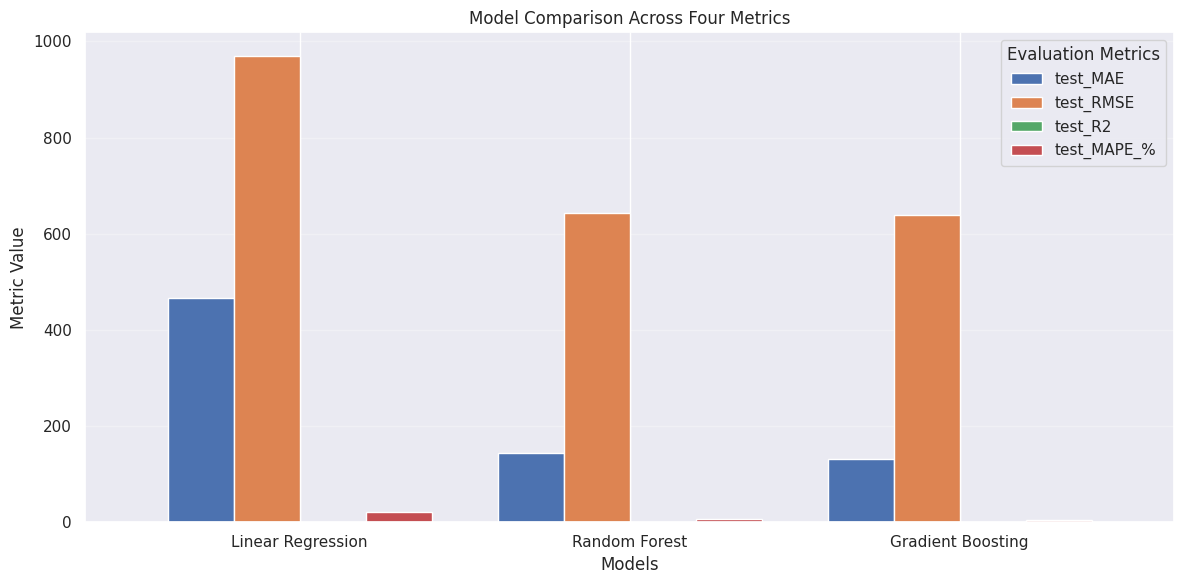

In [ ]:


# Create DataFrame containing the average metrics for each model
model_results = pd.DataFrame({
    "Linear Regression": average_lg,
    "Random Forest": average_rf,
    "Gradient Boosting": average_xgb
})

print(model_results)

# Four evaluation metrics
metrics = ["test_MAE", "test_RMSE", "test_R2", "test_MAPE_%"]

# Select metrics as rows and transpose
plot_data = model_results.loc[metrics].T

# Plot grouped bars
ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Model Comparison Across Four Metrics")
ax.set_xlabel("Models")
ax.set_ylabel("Metric Value")

# Use the model names on the x-axis
ax.set_xticklabels(plot_data.index, rotation=0)

ax.legend(title="Evaluation Metrics")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### Selected Model is Gradient Boosting

### let predict the posted rate for validation data

In [ ]:
val

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,TE-011996,Fort Wayne,Louisville,41.31561,-85.36206,37.36588,-87.47153,377.4,Dry Van,38638.0,2025-12-31,1.03391,2.15984
11996,TE-011997,Oklahoma City,Memphis,31.88294,-98.58097,35.56802,-89.52871,707.4,Dry Van,27685.0,2025-12-31,0.99846,2.46279
11997,TE-011998,Nashville,Montgomery,35.29479,-88.08915,31.37602,-86.10743,359.4,Flatbed,35522.0,2025-12-31,0.98564,2.09568
11998,TE-011999,Syracuse,San Antonio,42.80915,-76.89973,29.50969,-98.40059,1750.8,Dry Van,31755.0,2025-12-31,1.03100,1.95125


In [ ]:
val.dtypes

,0
load_id,object
pickup,object
delivery,object
pickup_lat,float64
pickup_lon,float64
delivery_lat,float64
delivery_lon,float64
distance,float64
equipment,object
weight,float64


In [ ]:
val['month']=val['date'].dt.month

In [ ]:
val.drop(columns=['pickup','delivery','quote_signal','load_id'],axis=1,inplace=True)

In [ ]:
X=df.drop(columns=['posted_rate'],axis=1)
y=df['posted_rate']

In [ ]:
X.head()

,date,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,market_index,month
0,2025-01-01,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,0.95684,1
1,2025-01-01,31.37602,-86.10743,39.62180,-88.48008,691.7,Dry Van,47500.0,0.95310,1
2,2025-01-01,39.55328,-72.18051,41.70243,-89.85588,1098.0,Dry Van,29071.0,0.96395,1
3,2025-01-01,39.55328,-72.18051,34.15334,-79.74475,684.1,Dry Van,25756.0,0.92209,1
4,2025-01-01,28.56624,-116.70249,39.54838,-118.64843,891.6,Dry Van,21332.0,0.97336,1


In [ ]:
pipe = TransformedTargetRegressor(
                regressor=xgb_model_pipeline,
                func=np.log,
                inverse_func=np.exp
            )

In [ ]:
pipe.fit(X,y)

TransformedTargetRegressor(func=<ufunc 'log'>, inverse_func=<ufunc 'exp'>,
                           regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('num',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(strategy='median')),
                                                                                                       ('scaler',
                                                                                                        StandardScaler())]),
                                                                                       ['weight',
                                                                                        'distance',
                                                                                        'pickup_lat',
                                                                                        'pickup_lon',
                                                                                        'delivery_lat',
                                                                                        'delivery_lon']),
                                                                                      ('cat',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(strategy='most_frequent')),
                                                                                                       ('onehot',
                                                                                                        OneHotEncoder(handle_unknown='ignore',
                                                                                                                      sparse_output=False))]),
                                                                                       ['equipment']),
                                                                                      ('market',
                                                                                       MarketIndexImputer(),
                                                                                       ['date',
                                                                                        'market_index']),
                                                                                      ('month',
                                                                                       'passthrough',
                                                                                       ['month'])])),
                                                     ('model',
                                                      GradientBoostingRegressor(learning_rate=0.05,
                                                                                max_depth=5,
                                                                                n_estimators=200,
                                                                                random_state=42,
                                                                                subsample=0.75))]))

In [ ]:
val.head()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,month
0,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,11
1,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,11
2,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,11
3,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,11
4,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,11


In [ ]:
val.tail()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,month
11995,41.31561,-85.36206,37.36588,-87.47153,377.4,Dry Van,38638.0,2025-12-31,1.03391,12
11996,31.88294,-98.58097,35.56802,-89.52871,707.4,Dry Van,27685.0,2025-12-31,0.99846,12
11997,35.29479,-88.08915,31.37602,-86.10743,359.4,Flatbed,35522.0,2025-12-31,0.98564,12
11998,42.80915,-76.89973,29.50969,-98.40059,1750.8,Dry Van,31755.0,2025-12-31,1.03100,12
11999,31.88294,-98.58097,29.87534,-99.85456,207.0,Dry Van,39571.0,2025-12-31,1.03809,12


In [ ]:
validation_posted_rate=pipe.predict(val)

In [ ]:
validation_posted_rate.shape

(12000,)

In [ ]:
validation_predictions_template=pd.read_csv('/content/validation-predictions-template.csv')

In [ ]:
validation_predictions_template['predicted_rate']=validation_posted_rate

In [ ]:
validation_predictions_template

,load_id,predicted_rate
0,TE-000001,875.985499
1,TE-000002,5097.558201
2,TE-000003,5179.731755
3,TE-000004,3977.863929
4,TE-000005,1849.920960
...,...,...
11995,TE-011996,875.811081
11996,TE-011997,1538.942079
11997,TE-011998,962.525726
11998,TE-011999,3425.229325


In [ ]:
validation_predictions_template.to_csv('validation_predictions_template_with_value.csv',index=False)

### December Chart

In [ ]:
df=pd.read_csv('/content/train-test.csv')

In [ ]:
val=pd.read_csv('/content/validation.csv')

In [ ]:
dec_data=pd.read_csv('/content/december-chart-inputs.csv')

In [ ]:
val

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,TE-011996,Fort Wayne,Louisville,41.31561,-85.36206,37.36588,-87.47153,377.4,Dry Van,38638.0,2025-12-31,1.03391,2.15984
11996,TE-011997,Oklahoma City,Memphis,31.88294,-98.58097,35.56802,-89.52871,707.4,Dry Van,27685.0,2025-12-31,0.99846,2.46279
11997,TE-011998,Nashville,Montgomery,35.29479,-88.08915,31.37602,-86.10743,359.4,Flatbed,35522.0,2025-12-31,0.98564,2.09568
11998,TE-011999,Syracuse,San Antonio,42.80915,-76.89973,29.50969,-98.40059,1750.8,Dry Van,31755.0,2025-12-31,1.03100,1.95125


#### The file has no lat/lon and no market_index, but the model needs them. Both can be taken from the data:


In [ ]:
allrows = pd.concat([df, val])
p = allrows[allrows.pickup == "Lexington"].iloc[0]; q = allrows[allrows.delivery == "Fort Wayne"].iloc[0]
print("Lexington (pickup):", p.pickup_lat, p.pickup_lon, "| Fort Wayne (delivery):", q.delivery_lat, q.delivery_lon)

Lexington (pickup): 36.99152 -84.99876 | Fort Wayne (delivery): 41.31561 -85.36206


In [ ]:
dec_data["pickup_lat"], dec_data["pickup_lon"] = p.pickup_lat, p.pickup_lon
dec_data["delivery_lat"], dec_data["delivery_lon"] = q.delivery_lat, q.delivery_lon

#### Now creating Market index column value from previous data

In [ ]:

# 2. Combine date and market_index from both datasets
all_feat = pd.concat(
    [
        df[["date", "market_index"]],
        val[["date", "market_index"]]
    ],
    ignore_index=True
)

# 3. Calculate one average market_index per calendar day
daily_mi = all_feat.groupby("date")["market_index"].mean()


# 5. Assign the daily market_index to each December date
dec_data["market_index"] = dec_data["date"].map(daily_mi)


In [ ]:
# 6. Check whether all dates have a value
print("Total December rows:", len(dec_data))
print("Missing market_index values:", dec_data["market_index"].isna().sum())

Total December rows: 31
Missing market_index values: 0


In [ ]:
dec_data.dtypes

,0
pickup,object
delivery,object
distance,int64
equipment,object
weight,int64
date,object
predicted_rate,float64
pickup_lat,float64
pickup_lon,float64
delivery_lat,float64


In [ ]:
dec_data['date'] = pd.to_datetime(dec_data['date'])

In [ ]:
dec_data['month']=dec_data['date'].dt.month

In [ ]:
dec_data.head(1)

,pickup,delivery,distance,equipment,weight,date,predicted_rate,pickup_lat,pickup_lon,delivery_lat,delivery_lon,market_index,month
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN,36.99152,-84.99876,41.31561,-85.36206,0.834919,12


In [ ]:
dec_data.drop(columns=['pickup','delivery','predicted_rate'],axis=1,inplace=True)

In [ ]:
dec_predicted_rate=pipe.predict(dec_data)

In [ ]:
decemeber_data=pd.read_csv('/content/december-chart-inputs.csv')

In [ ]:
decemeber_data['predicted_rate']=dec_predicted_rate

In [ ]:
decemeber_data.to_csv('december-chart-input-with-predicted-rate.csv')

In [ ]:
import pickle

In [1]:
# import joblib

# joblib.dump(pipe, "xgb_model_with_pipeline.pkl")